<a href="https://colab.research.google.com/github/mwangimarie43-art/100-days-ai-journey/blob/main/linear_models_predictive.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Linear Models for Predictive Modelling

**Contents**
1. What is a linear model?
2. Linearly separable data
3. Simple linear regression
4. Multiple linear regression
5. Polynomial regression
6. Limitations of linear models
7. Summary

**Focus:** we care about how well a model predicts *new, unseen* data. So every model is fit on a **training set** and judged on a **held-out test set**.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score
from sklearn.datasets import make_blobs, make_moons, load_diabetes

rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (6, 4)

def rmse(y, yhat):
    return np.sqrt(mean_squared_error(y, yhat))

## 1. What is a linear model?

A linear model predicts the target as a **weighted sum of the input features**:

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p$$

- $\beta_0$ is the **intercept** (prediction when every feature is 0).
- $\beta_j$ is the **weight** (slope) of feature $x_j$.

The weights are chosen to minimise the **sum of squared errors (SSE)** on the training data:

$$SSE = \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

The same "weighted sum" idea is used for **classification**: the sign of $\beta_0 + \beta^\top x$ decides the class, so the decision boundary is a straight line (or a flat plane / hyperplane in higher dimensions).

**How we measure predictive performance (regression)**

| Metric | Formula | Meaning |
|---|---|---|
| RMSE | $\sqrt{\frac{1}{n}\sum (y_i-\hat y_i)^2}$ | Typical size of a prediction error, in the units of $y$. Lower is better. |
| $R^2$ | $1 - \frac{SSE}{SST}$, with $SST=\sum (y_i-\bar y)^2$ | Share of the variability in $y$ that the model explains. 1 is perfect; 0 is no better than predicting the mean. |

RMSE is not a *relative* metric (an error of 178 is huge for coffee prices, tiny for mountain heights in cm), which is why $R^2$ is useful for comparing models across datasets.

## 2. Linearly separable data

Two classes are **linearly separable** if a single straight line (hyperplane) can split them perfectly. A linear classifier (e.g. logistic regression, perceptron) can then reach 100% accuracy.

If the classes curl around each other, no straight line can separate them and a linear classifier will make errors no matter how it is tuned.

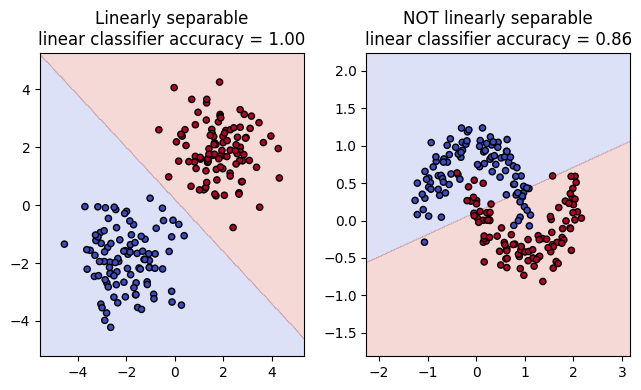

In [ ]:
X_sep, y_sep = make_blobs(n_samples=200, centers=[(-2, -2), (2, 2)],
                          cluster_std=1.0, random_state=0)
X_moon, y_moon = make_moons(n_samples=200, noise=0.15, random_state=0)

def plot_boundary(ax, X, y, title):
    clf = LogisticRegression().fit(X, y)
    xx, yy = np.meshgrid(np.linspace(X[:,0].min()-1, X[:,0].max()+1, 300),
                         np.linspace(X[:,1].min()-1, X[:,1].max()+1, 300))
    zz = clf.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.2, cmap="coolwarm")
    ax.scatter(X[:,0], X[:,1], c=y, cmap="coolwarm", edgecolor="k", s=20)
    acc = accuracy_score(y, clf.predict(X))
    ax.set_title(f"{title}\nlinear classifier accuracy = {acc:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(6.5, 4))
plot_boundary(axes[0], X_sep, y_sep, "Linearly separable")
plot_boundary(axes[1], X_moon, y_moon, "NOT linearly separable")
plt.tight_layout(); plt.show()

**Takeaway:** a linear model can only draw straight boundaries. When the true pattern is curved, we either need to engineer new features (e.g. polynomial terms, Section 5) or use a non-linear model.

## 3. Simple linear regression

One feature, one straight line: $\hat{y} = \beta_0 + \beta_1 x$.

Example: predict a house price (in \$1000s) from its size (in m²), using simulated data.

In [ ]:
size = rng.uniform(40, 200, 150)                      # m^2
price = 50 + 2.5 * size + rng.normal(0, 40, 150)      # true line + noise
df = pd.DataFrame({"size": size, "price": price})

X_train, X_test, y_train, y_test = train_test_split(df[["size"]], df["price"],
                                                test_size=0.3, random_state=1)

slr = LinearRegression().fit(X_train, y_train)
print(f"Fitted model:  price = {slr.intercept_:.1f} +{slr.coef_[0]:.2f} * size")

for name, X_, y_ in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
    p = slr.predict(X_)
    print(f"{name:5s}  RMSE = {rmse(y_, p):6.2f}   R^2 = {r2_score(y_, p):.3f}")

Fitted model:  price = 47.6 +2.52 * size
Train  RMSE =  38.95   R^2 = 0.899
Test   RMSE =  43.93   R^2 = 0.865


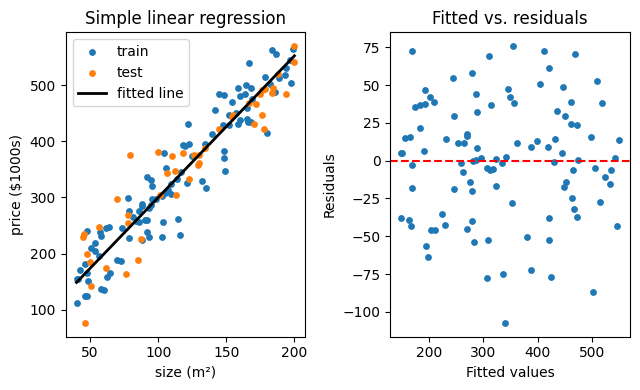

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(6.5, 4))
grid = pd.DataFrame({"size": np.linspace(40, 200, 100)})
axes[0].scatter(X_train, y_train, s=15, label="train")
axes[0].scatter(X_test, y_test, s=15, label="test")
axes[0].plot(grid, slr.predict(grid), "k", lw=2, label="fitted line")
axes[0].set(xlabel="size (m²)",
            ylabel="price ($1000s)",
            title="Simple linear regression"); axes[0].legend()

fitted = slr.predict(X_train); resid = y_train - fitted
axes[1].scatter(fitted, resid, s=15); axes[1].axhline(0, color="r", ls="--")
axes[1].set(xlabel="Fitted values", ylabel="Residuals",
            title="Fitted vs. residuals")
plt.tight_layout(); plt.show()

**Reading the fitted-vs-residuals plot.** Slice the x-axis into narrow windows. If *every* window has a roughly even mix of positive and negative residuals, a straight line is a suitable model. A window dominated by one sign signals a non-linear relationship (we will see this in Section 5).

**Predicting new data.** Once fitted, prediction is just plugging into the equation:

In [ ]:
new_houses = pd.DataFrame({"size": [80, 120, 180]})
print(pd.DataFrame({"size": new_houses["size"],
              "predicted price": slr.predict(new_houses).round(1)}))

   size  predicted price
0    80            249.5
1   120            350.5
2   180            501.9


## 4. Multiple linear regression

Several features at once: $\hat{y} = \beta_0 + \beta_1 x_1 + \dots + \beta_p x_p$. With two features the model is a flat plane; with more it is a hyperplane.

We use scikit-learn's **diabetes** dataset: 10 baseline measurements (age, BMI, blood pressure, 6 blood serum values …) for 442 patients; the target is a measure of disease progression one year later.

In [ ]:
data = load_diabetes(as_frame=True)
X, y = data.data, data.target
print(X.shape); X.head()

(442, 10)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30,
                                                    random_state=0)

# Baseline 1: predict the training mean for everyone
base = np.full(len(y_test), y_train.mean())
# Baseline 2: simple regression on BMI only
slr_bmi = LinearRegression().fit(X_train[["bmi"]], y_train)
# Multiple regression on all 10 features
mlr = LinearRegression().fit(X_train, y_train)

results = pd.DataFrame({
    "model": ["Mean only", "Simple (BMI)", "Multiple (10 features)"],
    "test RMSE": [rmse(y_test, base), rmse(y_test,
    slr_bmi.predict(X_test[["bmi"]])), rmse(y_test, mlr.predict(X_test))],
    "test R^2": [r2_score(y_test, base), r2_score(y_test,
    slr_bmi.predict(X_test[["bmi"]])), r2_score(y_test, mlr.predict(X_test))],
}).round(3)
results

,model,test RMSE,test R^2
0,Mean only,71.425,-0.000
1,Simple (BMI),62.621,0.231
2,Multiple (10 features),55.652,0.393


Adding relevant features lowers test error. Note that the **training** score will always look at least as good as the test score, because the weights were tuned on the training data; the **test** score is the honest estimate of performance on new patients.

**Interpreting weights (briefly).** Each weight says: *if this feature increases by one unit and all other features stay fixed, the prediction changes by $\beta_j$*. Because features have different scales, only compare weight sizes after standardising the features (the diabetes features are already scaled).

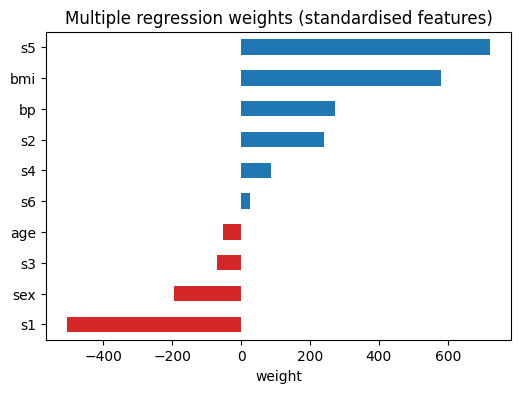

In [ ]:
coef = pd.Series(mlr.coef_, index=X.columns).sort_values()
coef.plot.barh(color=np.where(coef > 0, "tab:blue", "tab:red"))
plt.title("Multiple regression weights (standardised features)");
plt.xlabel("weight"); plt.show()

**Adjusted $R^2$.** Plain $R^2$ on the training data never decreases when you add a feature – even pure noise. Adjusted $R^2$ penalises extra features:

$$\bar R^2 = 1 - (1-R^2)\frac{n-1}{n-p-1}$$

For prediction, the more direct check is simply the **test-set** score.

In [ ]:
def adj_r2(r2, n, p): return 1 - (1 - r2) * (n - 1) / (n - p - 1)

Xn_train = X_train.copy(); Xn_test = X_test.copy()
for k in range(30):  # add 30 pure-noise columns
    Xn_train[f"noise{k}"] = rng.normal(size=len(Xn_train))
    Xn_test[f"noise{k}"]  = rng.normal(size=len(Xn_test))

rows = []
for label, A, B in [("10 real features", X_train, X_test),
 ("+30 noise features", Xn_train, Xn_test)]:
    m = LinearRegression().fit(A, y_train)
    r2_tr = r2_score(y_train, m.predict(A))
    rows.append([label, r2_tr, adj_r2(r2_tr, len(A), A.shape[1]),
                 r2_score(y_test, m.predict(B))])
pd.DataFrame(rows, columns=["model", "train R^2", "train adj R^2",
                            "test R^2"]).round(3)

,model,train R^2,train adj R^2,test R^2
0,10 real features,0.554,0.539,0.393
1,+30 noise features,0.581,0.519,0.360


Train $R^2$ went **up** with 30 useless features, yet test $R^2$ went **down** – a first look at overfitting. Adjusted $R^2$ shrinks the gain but does not fully remove it, which is why the test set is the more reliable judge for prediction.

## 5. Polynomial regression

When the relationship is curved, we can still use a linear model by adding **powers of the feature** as new columns:

$$\hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2 + \dots + \beta_d x^d$$

This is still *linear in the weights* (so it is fit exactly like multiple regression), but the curve in $x$ can bend. The degree $d$ controls flexibility:
- too low → **underfitting** (misses the pattern),
- too high → **overfitting** (memorises noise, poor on new data).

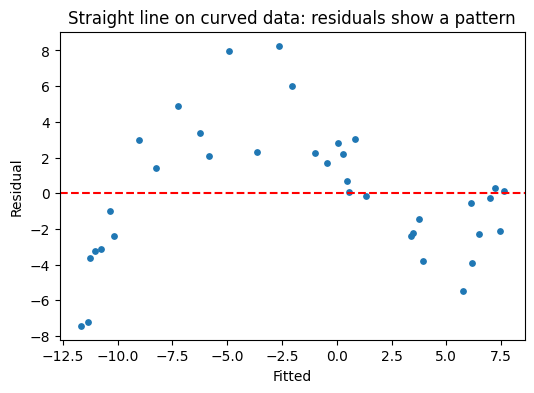

In [ ]:
x = np.sort(rng.uniform(-3, 3, 60))
y_curve = 0.5 * x**3 - x**2 + 2 + rng.normal(0, 1.5, 60)
x_tr, x_te, y_tr, y_te = train_test_split(x.reshape(-1, 1), y_curve,
                                          test_size=0.4, random_state=3)

# Straight line on curved data -> look at the residuals
lin = LinearRegression().fit(x_tr, y_tr)
fit_l = lin.predict(x_tr)
plt.scatter(fit_l, y_tr - fit_l, s=15); plt.axhline(0, color="r", ls="--")
plt.title("Straight line on curved data: residuals show a pattern");
plt.xlabel("Fitted"); plt.ylabel("Residual"); plt.show()

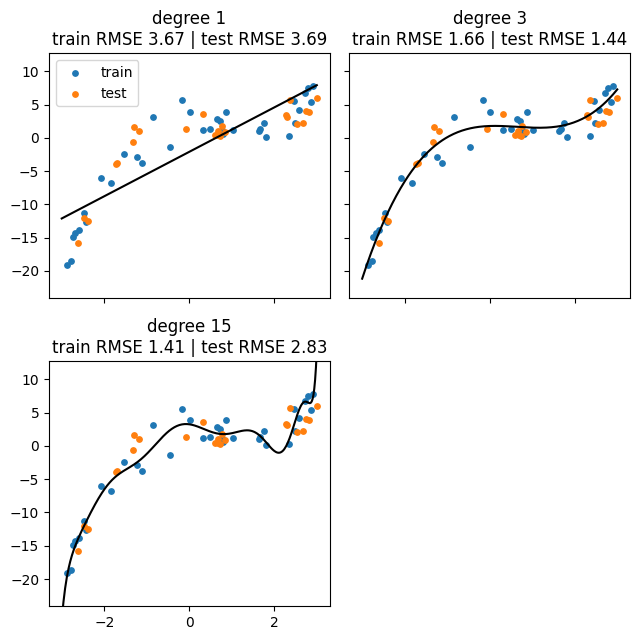

In [ ]:
grid = np.linspace(-3, 3, 300).reshape(-1, 1)
fig, axes = plt.subplots(2, 2, figsize=(6.5, 6.5), sharex=True, sharey=True)
axes = axes.ravel()
for ax, d in zip(axes, [1, 3, 15]):
    model = make_pipeline(PolynomialFeatures(d, include_bias=False),
                          StandardScaler(), LinearRegression()).fit(x_tr, y_tr)
    ax.scatter(x_tr, y_tr, s=15, label="train"); ax.scatter(x_te, y_te, s=15,
                                                            label="test")
    ax.plot(grid, model.predict(grid), "k")
    ax.set_ylim(y_curve.min() - 5, y_curve.max() + 5)
    ax.set_title(f"degree {d}\ntrain RMSE {rmse(y_tr,
  model.predict(x_tr)):.2f} | test RMSE {rmse(y_te, model.predict(x_te)):.2f}")
axes[3].axis("off")
axes[0].legend(); plt.tight_layout(); plt.show()

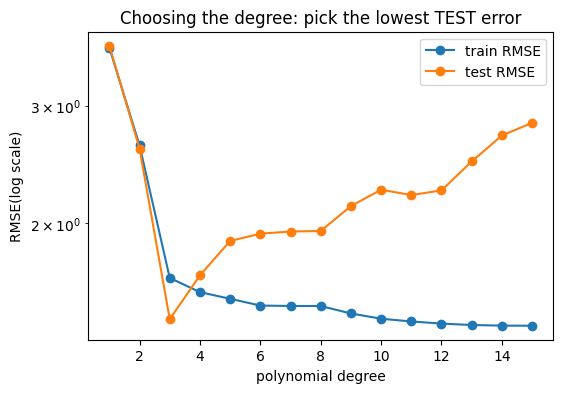

Best degree by test RMSE: 3


In [ ]:
degrees = range(1, 16)
tr_err, te_err = [], []
for d in degrees:
    m = make_pipeline(PolynomialFeatures(d, include_bias=False),
                      StandardScaler(), LinearRegression()).fit(x_tr, y_tr)
    tr_err.append(rmse(y_tr, m.predict(x_tr))); te_err.append(rmse(y_te,
                                                              m.predict(x_te)))

plt.plot(degrees, tr_err, "o-", label="train RMSE"); plt.plot(degrees, te_err,
                                                        "o-", label="test RMSE")
plt.yscale("log"); plt.xlabel("polynomial degree");plt.ylabel("RMSE(log scale)")
plt.title("Choosing the degree: pick the lowest TEST error"); plt.legend();
plt.show()
print("Best degree by test RMSE:", degrees[int(np.argmin(te_err))])

Training error keeps falling as the degree rises, but test error bottoms out (near the true degree, 3) and then climbs. **Always choose model complexity using held-out data** (a test set, or better, cross-validation).

## 6. Limitations of linear models

### 6.1 Only linear (additive) relationships
The model is a weighted sum. Curves and **interactions** (e.g. the effect of dose depends on age) are not learned automatically – each must be hand-crafted as a new feature (like the $x^2$ terms above). On complex real-world data, this often means linear models **predict less accurately** than flexible models such as tree ensembles.

### 6.2 Extrapolation
A model is only trustworthy inside the range of the training data. Outside it, the line just continues – whether or not reality does.

### 6.3 Multicollinearity (correlated features)
If two features carry almost the same information, the model cannot tell which one deserves the credit. Weights become unstable and can even flip sign, and the extra feature can hurt test performance.

Below we copy the BMI column, change a **single value**, and fit both copies together.

In [ ]:
Xc_train = X_train.copy(); Xc_test = X_test.copy()
Xc_train["bmi_copy"] = Xc_train["bmi"]; Xc_test["bmi_copy"] = Xc_test["bmi"]
Xc_train.iloc[0, Xc_train.columns.get_loc("bmi_copy")] += 0.05 # one tiny edit

m_one  = LinearRegression().fit(X_train[["bmi"]], y_train)
m_both = LinearRegression().fit(Xc_train[["bmi", "bmi_copy"]], y_train)

print("Correlation bmi vs bmi_copy: %.4f" % Xc_train[["bmi",
                                              "bmi_copy"]].corr().iloc[0, 1])
print("BMI only   -> weight: %.0f" % m_one.coef_[0])
print("BMI + copy -> weights: bmi = %.0f, bmi_copy = %.0f" %tuple(m_both.coef_))
print("Test R^2  one: %.3f   both: %.3f" % (r2_score(y_test,
                                            m_one.predict(X_test[['bmi']])),
      r2_score(y_test, m_both.predict(Xc_test[['bmi', 'bmi_copy']]))))

Correlation bmi vs bmi_copy: 0.9983
BMI only   -> weight: 1013
BMI + copy -> weights: bmi = -1100, bmi_copy = 2113
Test R^2  one: 0.231   both: 0.232


Practically the same feature now gets two large weights with **opposite signs**, even though BMI on its own has a clear positive effect. Predictions (and test $R^2$) are almost unchanged here, so the model still *predicts* fine – but the weights are no longer trustworthy, and with many correlated features the instability can also hurt generalisation. Fixes: drop one of each highly correlated pair (check `X.corr()`), or use regularisation.

### 6.4 Too many features → overfitting
As shown in Section 4, adding features always helps the training fit, even when they are noise. **Lasso** regression adds a penalty $\lambda \sum |\beta_j|$ that shrinks weights and sets many to exactly 0, giving a smaller model that often predicts better.

In [ ]:
lasso = make_pipeline(StandardScaler(), Lasso(alpha=3.0)).fit(Xn_train, y_train)
ols   = LinearRegression().fit(Xn_train, y_train)
n_kept = (lasso[-1].coef_ != 0).sum()
print(f"Ordinary LR (40 features): test R^2 = {r2_score(y_test,
                                                    ols.predict(Xn_test)):.3f}")
print(f"Lasso       (keeps {n_kept} of 40): test R^2 = {r2_score(y_test,
                                                 lasso.predict(Xn_test)):.3f}")

Ordinary LR (40 features): test R^2 = 0.360
Lasso       (keeps 13 of 40): test R^2 = 0.398


### 6.5 Statistical assumptions
For pure prediction, the assumptions below are not strictly required, but when they fail, error bars and confidence intervals become unreliable and predictions may be systematically off in parts of the data:

| Assumption | What it means | Typical violation |
|---|---|---|
| Linearity | $y$ is a linear function of the features | curved relationships (Section 5) |
| Homoscedasticity | error spread is the same everywhere | errors grow with house price |
| Independence | each row is independent | repeated measurements on the same patient |
| Normality of errors | errors are roughly bell-shaped | heavy outliers |
| Fixed features | features are measured without error | noisy sensors / surveys |
| No multicollinearity | features not strongly correlated | size vs. number of rooms |

### 6.6 Interpretation caveats
Each weight is interpreted "with all other features held fixed", which may describe an unrealistic situation (more rooms but the same floor area). The intercept describes a point where every feature is 0, which is often meaningless unless features are centred.